# Simulation Files for Deneb L2 flight with Dual Deploy
Simulation files mirror Deneb, based on a Warrior Jr airframe with the dual deploy configuration.

Currently a WIP. Current code highlights defining a rocket from the ground up, however plan is to pull bulk of data from openrocket using rocketserializer.


Gravity Details

Acceleration of gravity at surface level:    9.8040 m/s²
Acceleration of gravity at  78.648 km (ASL): 9.5664 m/s²


Launch Site Details

Launch Date: 2026-11-12 12:00:00 UTC
Launch Site Latitude: 43.26272°
Launch Site Longitude: -86.03229°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 91545.96 W    4802299.14 N
Launch Site UTM zone: 17T
Launch Site Surface Elevation: 212.0 m


Atmospheric Model Details

Atmospheric Model Type: forecast
forecast Maximum Height: 78.648 km

Surface Atmospheric Conditions

Surface Wind Speed: 8.15 m/s
Surface Wind Direction: 341.61°
Surface Wind Heading: 161.61°
Surface Pressure: 983.17 hPa
Surface Temperature: 278.15 K
Surface Air Density: 1.231 kg/m³
Surface Speed of Sound: 334.34 m/s


Earth Model Details

Earth Radius at Launch site: 6368.14 km
Semi-major Axis: 6378.14 km
Semi-minor Axis: 6356.75 km
Flattening: 0.0034


Atmospheric Model Plots



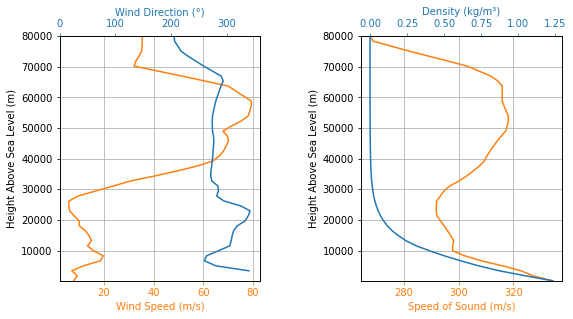

In [3]:
from rocketpy import Environment, Motor, Rocket, Flight
import datetime

# MMAR launch site. Check elevation later.
env = Environment(latitude=43.262715, longitude=-86.032290, elevation=191.4)

tomorrow = datetime.date.today() + datetime.timedelta(days=1)

env.set_date(
    (tomorrow.year, tomorrow.month, tomorrow.day, 12)
)  # Hour given in UTC time

env.set_atmospheric_model(type="forecast", file="GFS")

env.info()


Nozzle Details
Nozzle Radius: 0.009 m
Nozzle Throat Radius: 0.0045 m

Grain Details
Number of Grains: 1
Grain Spacing: 0.0 m
Grain Density: 1712.0 kg/m3
Grain Outer Radius: 0.017 m
Grain Inner Radius: 0.006 m
Grain Height: 0.28 m
Grain Volume: 0.000 m3
Grain Mass: 0.381 kg

Motor Details
Total Burning Time: 2.563 s
Total Propellant Mass: 0.381 kg
Structural Mass Ratio: 0.407
Average Propellant Exhaust Velocity: 1841.099 m/s
Average Thrust: 273.691 N
Maximum Thrust: 367.585 N at 0.007 s after ignition.
Total Impulse: 701.470 Ns



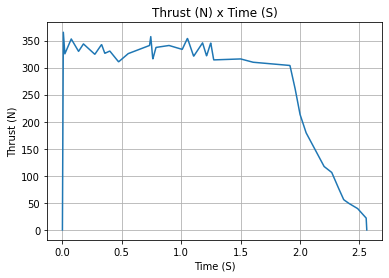

In [5]:
# Solid Motor Definition
from rocketpy import SolidMotor

j270 = SolidMotor(
    thrust_source = "Motors/AeroTech_HP-J270W.eng",
    burn_time=(0.0, 2.563),
    dry_mass=0.261,

    # NOTE: Values below are from chat. Should confirm further.

    # Estimated using a thin cylindrical shell
    dry_inertia=(0.00281, 0.00281, 0.0000942),

    # Assumed nozzle geometry—not verified J270W dimensions
    nozzle_radius=0.009,
    throat_radius=0.0045,

    # Equivalent single grain—not the actual internal configuration.
    # Density chosen to give approximately 0.381 kg of propellant.
    grain_number=1,
    grain_density=1712.0,
    grain_outer_radius=0.017,
    grain_initial_inner_radius=0.006,
    grain_initial_height=0.280,
    grain_separation=0.0,

    # Estimated positions, measured forward from the nozzle outlet
    grains_center_of_mass_position=0.1782,
    center_of_dry_mass_position=0.1782,
    nozzle_position=0.0,

    interpolation_method="linear",
    reshape_thrust_curve=False,
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)

j270.info()

In [ ]:
from rocketpy import Rocket
